# Primera Red Neuronal Profunda
En este notebook se aplicara todo lo visto durante el primer parcial de Aprendizaje Profundo. <br>
Para la aplicación de estos conocimientos se ha optado por 



## Metricas realizadas con otros métodos
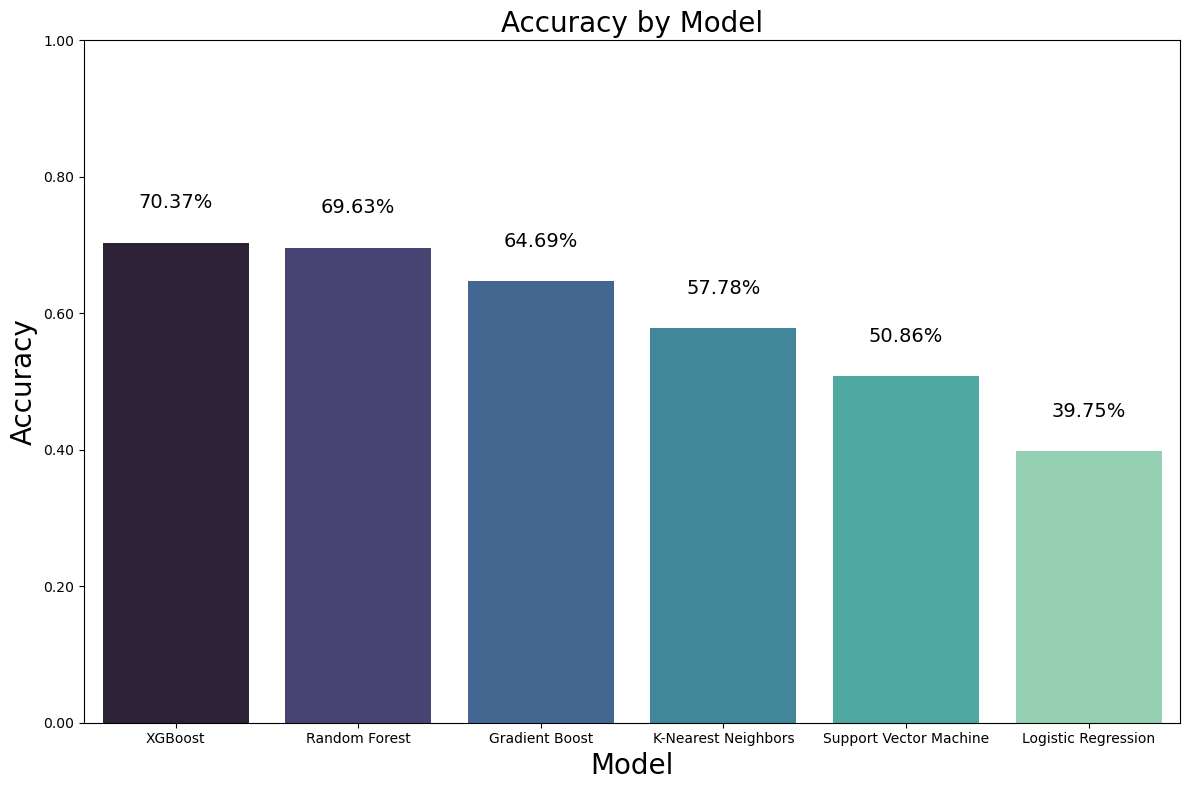

## Liberias y dataset

In [1]:
# Librerias  
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks

### Importación del dataset y target

In [2]:
# Carga del conjunto de datos con datos explicitos
df = pd.read_csv('Data/CorporateCredit.csv',
dtype={
        'Rating Agency': 'category',
        'Rating': 'category',
        'Binary Rating': 'boolean',
        'SIC Code': 'string',
        'Sector': 'category',
        'Ticker': 'string'
    }
)
target = 'Rating'

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7805 entries, 0 to 7804
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   Rating Agency                  7805 non-null   category
 1   Corporation                    7805 non-null   str     
 2   Rating                         7805 non-null   category
 3   Rating Date                    7805 non-null   str     
 4   CIK                            7805 non-null   int64   
 5   Binary Rating                  7805 non-null   boolean 
 6   SIC Code                       7805 non-null   string  
 7   Sector                         7805 non-null   category
 8   Ticker                         7805 non-null   string  
 9   Current Ratio                  7805 non-null   float64 
 10  Long-term Debt / Capital       7805 non-null   float64 
 11  Debt/Equity Ratio              7805 non-null   float64 
 12  Gross Margin                   7805 non-null 

C:\Users\kevin\AppData\Local\Temp\ipykernel_24092\1897345634.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


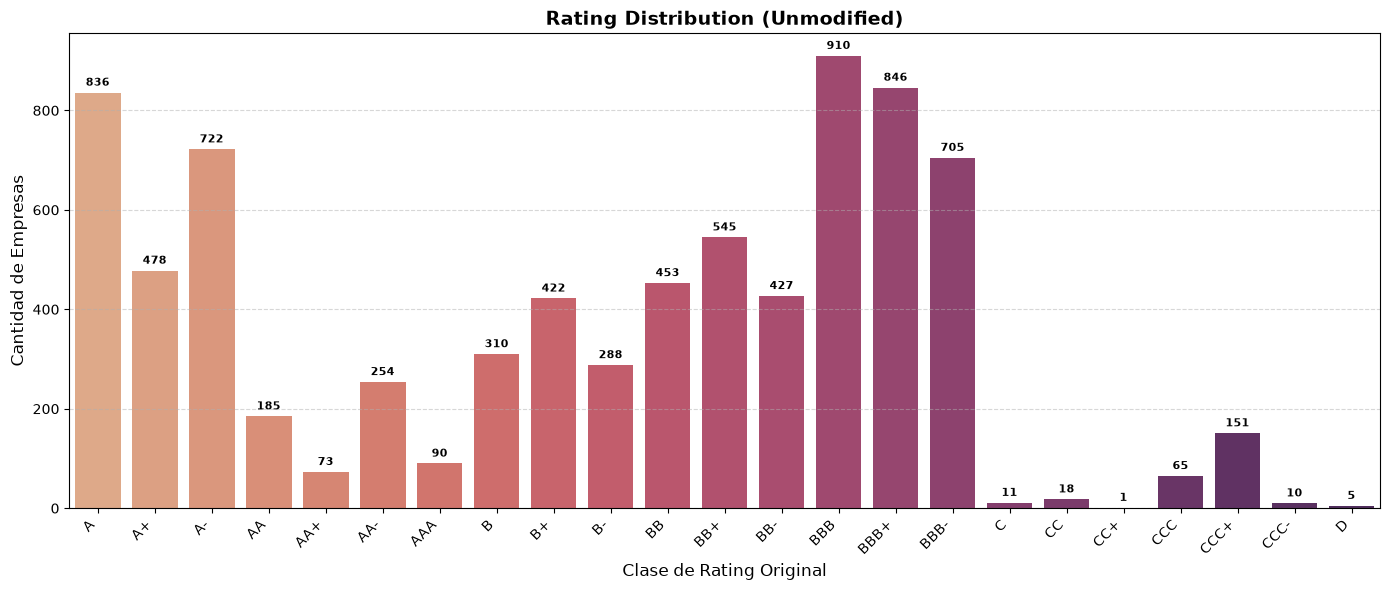

In [4]:
# 2. Configuración de lienzo ampliado para albergar 23 columnas
fig, ax = plt.subplots(figsize=(14, 6))

# 3. Gráfico de distribución original
sns.countplot(
    data=df, 
    x=target,  
    palette="flare", 
    ax=ax
)

# 4. Formato y etiquetas
ax.set_title("Rating Distribution (Unmodified)", fontsize=14, fontweight='bold')
ax.set_xlabel("Clase de Rating Original", fontsize=12)
ax.set_ylabel("Cantidad de Empresas", fontsize=12)

# Rotación de etiquetas a 45 grados y cuadrícula vertical de soporte
plt.xticks(rotation=45, ha='right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Anotación numérica sobre cada barra (manejando clases con 0 registros)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', 
            xytext=(0, 3), textcoords='offset points',
            fontsize=8, fontweight='bold'
        )

plt.tight_layout()
plt.show()

## Preprocesamiento de los datos

In [5]:
FUSIONAR_DEFAULT = True   # True -> 8 clases (D dentro de CCC-C) | False -> 9 clases

columnas_descarte = ['CIK', 'Corporation', 'Binary Rating', 'Rating Date', 'Ticker', 'SIC Code']
df = df.drop(columns=columnas_descarte, errors='ignore')
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n_antes - len(df)} (quedan {len(df)} filas)")

RATING_MAP = {
    'AAA': 0, 'AA+': 0, 'AA': 0, 'AA-': 0,
    'A+': 1,
    'A': 2,
    'A-': 3,
    'BBB+': 4, 'BBB': 4, 'BBB-': 4,
    'BB+': 5, 'BB': 5, 'BB-': 5,
    'B+': 6, 'B': 6, 'B-': 6,
    'CCC+': 7, 'CCC': 7, 'CCC-': 7, 'CC+': 7, 'CC': 7, 'C': 7,
    'D': 7 if FUSIONAR_DEFAULT else 8
}

CLASS_NAMES = {
    0: 'AAA/AA', 1: 'A+', 2: 'A', 3: 'A-', 4: 'BBB', 5: 'BB', 6: 'B',
    7: 'CCC-C+D' if FUSIONAR_DEFAULT else 'CCC-C', 8: 'D'
}

df[target] = df[target].astype(str).map(RATING_MAP)

nulos_generados = df[target].isnull().sum()
if nulos_generados > 0:
    print(f"Advertencia: Se descartaron {nulos_generados} registros sin mapeo.")
    df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

X_ORDER = sorted(df[target].unique())
X_LABELS = [CLASS_NAMES[i] for i in X_ORDER]
print(f"Clases finales: {len(X_ORDER)} -> {X_LABELS}")
print(df[target].value_counts().sort_index().to_string())

X = df.drop(columns=[target])
y = df[target]

Duplicados eliminados: 2551 (quedan 5254 filas)
Clases finales: 8 -> ['AAA/AA', 'A+', 'A', 'A-', 'BBB', 'BB', 'B', 'CCC-C+D']
Rating
0     352
1     254
2     535
3     434
4    1672
5    1038
6     767
7     202


## Train, Dev y Test

In [6]:
# 7. Partición Estratificada Tridimensional (80% Train, 10% Dev, 10% Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
strat_temp = y_temp if y_temp.value_counts().min() >= 2 else None
if strat_temp is None:
    print("Aviso: alguna clase tiene <2 muestras en el bloque temporal; Dev/Test sin estratificar.")
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=strat_temp
)

In [7]:
# 8. Identificación de Columnas para el Pipeline
columnas_categoricas = ['Rating Agency', 'Sector']
columnas_numericas = X.select_dtypes(include=['float64']).columns.tolist()


### Normalización de los datos
**Estandarización Z-Score (StandardScaler)** 
Transforma cada característica numérica para que tenga media $\mu = 0$ y desviación estándar $\sigma = 1$:

$$z = \frac{x - \mu}{\sigma}$$

Razón de selección: Como se observó en el desglose estadístico (.describe()), existen ratios con valores atípicos extremos como ROE ($\min = -11,258.21$, $\max = 7,038.46$). La estandarización preserve la distancia relativa de los datos extremos sin comprimir la varianza del resto de las observaciones.

In [8]:
# 9. Pipeline de Transformación de Características
preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), columnas_categoricas)
    ]
)

In [9]:
df.head()


,Rating Agency,Rating,Sector,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
0,Standard & Poor's Ratings Services,3,Utils,1.1507,0.4551,0.8847,77.6230,19.4839,19.4839,28.9834,13.6093,8.3224,0.3173,8.1724,8.1978,2.6385,4.4530,1.9957,-0.1333
1,Standard & Poor's Ratings Services,0,BusEq,1.1129,0.0072,0.0073,43.6619,19.8327,19.8327,23.9379,20.8699,13.5690,0.3324,22.0354,47.2858,4.4944,21.8765,0.2501,0.3132
2,Standard & Poor's Ratings Services,4,Shops,1.9276,0.2924,0.4255,11.9008,3.3173,3.3173,3.6338,3.0536,2.1418,2.4620,13.6376,16.7991,5.2731,9.6494,-7.6079,-7.3231
3,Standard & Poor's Ratings Services,0,Utils,0.8358,0.4708,0.9491,64.5096,18.4549,18.4549,27.9377,15.1135,9.0246,0.2946,9.6412,9.7015,2.6583,5.1018,1.7438,-0.8999
4,Standard & Poor's Ratings Services,2,Shops,1.2931,0.2644,0.4036,3.8385,1.3269,1.3269,1.5847,1.2304,0.6518,4.9276,11.1256,19.4184,2.9364,8.1844,1.9725,2.4174


In [10]:
df.describe()

,Rating,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
count,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000
mean,3.905596,1.922544,0.463649,-0.261848,42.174783,11.002326,11.053951,19.662857,8.044245,5.426744,0.855888,11.605905,21.198408,4.377956,6.872244,0.561743,0.038001
std,1.765264,1.896909,2.945334,39.748907,23.869516,27.208801,27.221122,25.783220,29.365457,25.559534,0.695256,243.781916,484.605006,9.885252,24.514138,6.943983,7.735474
min,0.000000,0.174900,-86.363600,-1473.098000,-87.684000,-461.787800,-461.787800,-360.816900,-476.010000,-414.824800,0.068400,-11258.210000,-14023.260000,-226.442500,-745.454500,-91.330200,-130.665800
25%,3.000000,1.077500,0.286300,0.412700,22.104500,5.856100,5.896575,10.711300,3.621800,2.435900,0.400750,5.594300,-11.052300,2.243000,3.372325,-0.463800,-0.760600
50%,4.000000,1.513750,0.428950,0.760650,39.102600,11.903200,11.976200,18.168200,9.409600,6.726050,0.666100,12.024200,10.335100,4.629700,7.191750,0.230000,0.107400
75%,5.000000,2.172100,0.547650,1.218800,59.467650,19.079200,19.119125,30.410975,16.125600,11.895475,1.045675,20.009300,26.007375,7.768100,12.361500,1.111200,1.005500
max,7.000000,34.076800,171.500000,194.375000,100.000000,93.993000,93.993000,286.493500,221.289400,219.390300,8.503900,7038.461000,9882.979000,114.716900,466.666700,282.192100,107.737700


In [11]:
# 10. Ajuste e Inferencia en Tensores Disjuntos
X_train_proc = preprocesador.fit_transform(X_train)
X_dev_proc = preprocesador.transform(X_dev)
X_test_proc = preprocesador.transform(X_test)

print(f"Número de clases objetivo: {len(X_ORDER)}")
print(f"Dimensiones de X_train_proc: {X_train_proc.shape}")
print(f"Dimensiones de X_dev_proc: {X_dev_proc.shape}")
print(f"Dimensiones de X_test_proc: {X_test_proc.shape}")


Número de clases objetivo: 8
Dimensiones de X_train_proc: (4203, 33)
Dimensiones de X_dev_proc: (525, 33)
Dimensiones de X_test_proc: (526, 33)


### Ploteo Target

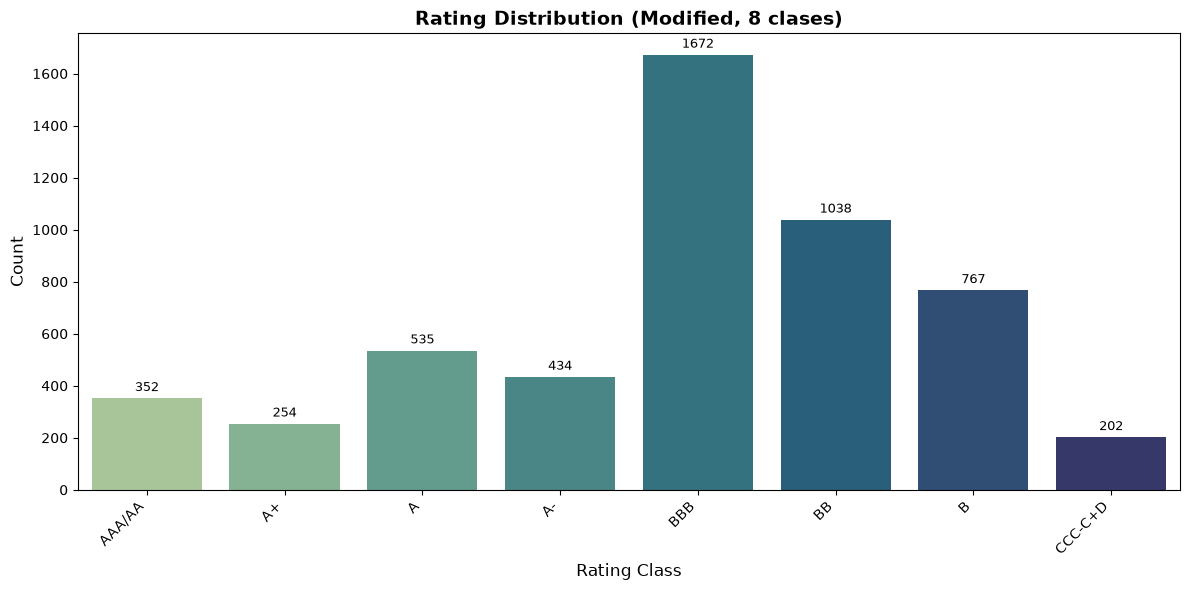

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=df, x=target, order=X_ORDER, hue=target, hue_order=X_ORDER,
              palette="crest", legend=False, ax=ax)
ax.set_title(f"Rating Distribution (Modified, {len(X_ORDER)} clases)", fontsize=14, fontweight='bold')
ax.set_xlabel("Rating Class", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_xticks(range(len(X_ORDER)))
ax.set_xticklabels(X_LABELS, rotation=45, ha='right')
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)
plt.tight_layout()
plt.savefig('rating_distribution_modified.png')
plt.show()

### Mapa de calor variables

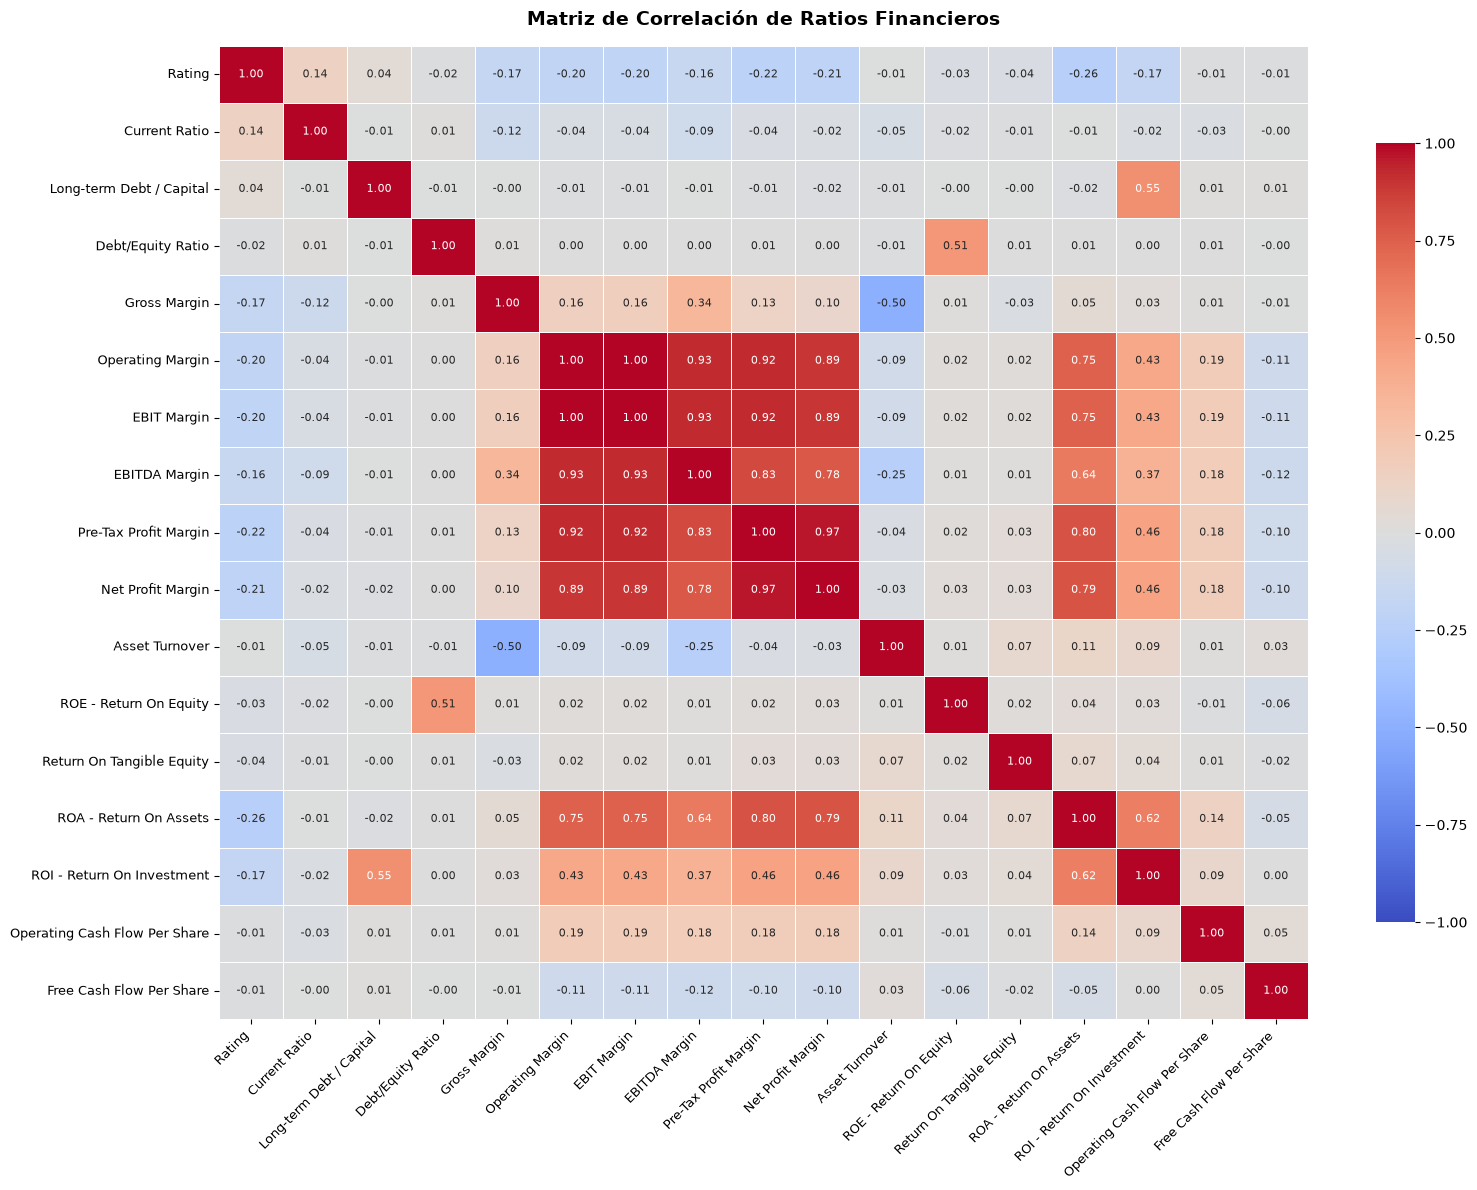

In [13]:
# 1. Ajuste de dimensiones del lienzo para albergar las ~16 variables numéricas
fig, ax = plt.subplots(figsize=(16, 12))

# 2. Matriz de correlación restringida a tipos numéricos
corr_matrix = df.select_dtypes(include='number').corr()

# 3. Mapa de calor con escala divergente y tamaño de fuente ajustado por celda
sns.heatmap(
    corr_matrix, 
    ax=ax, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8}
)

# 4. Alineación y rotación de nombres de columnas para evitar superposición
ax.set_title("Matriz de Correlación de Ratios Financieros", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

## Keras

In [14]:
from sklearn.metrics import f1_score

def construir_modelo(cfg):
    """Construye un MLP a partir de un diccionario de configuración."""
    capas      = cfg.get('capas', (32,))
    activacion = cfg.get('activacion', 'relu')
    batchnorm  = cfg.get('batchnorm', False)
    dropout    = cfg.get('dropout', 0.0)
    l1         = cfg.get('l1', 0.0)
    l2         = cfg.get('l2', 0.0)
    init       = 'he_normal' if activacion == 'relu' else 'glorot_uniform'
    reg = regularizers.L1L2(l1=l1, l2=l2) if (l1 or l2) else None

    m = models.Sequential([layers.Input(shape=(input_dim,))])
    for n in capas:
        m.add(layers.Dense(n, kernel_initializer=init, kernel_regularizer=reg))
        if batchnorm:
            m.add(layers.BatchNormalization())
        m.add(layers.Activation(activacion))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(num_classes))  # logits

    lr  = cfg.get('learning_rate', 1e-3)
    opt = cfg.get('optimizador', 'adam')
    if opt == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr)
    elif opt == 'momentum':
        optimizer = tf.keras.optimizers.SGD(learning_rate=lr, momentum=cfg.get('momentum', 0.9))
    elif opt == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=lr)
    else:
        optimizer = tf.keras.optimizers.Adam(learning_rate=lr)

    m.compile(
        optimizer=optimizer,
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            tf.keras.metrics.SparseCategoricalCrossentropy(from_logits=True, name='ce'),
            tf.keras.metrics.SparseCategoricalAccuracy(name='acc'),
        ],
    )
    return m


def entrenar(cfg, epocas=10, paciencia=3, batch_size=256, semilla=42, verbose=0):
    """Entrena con early stopping sobre la CE de dev. Devuelve (modelo, historial)."""
    tf.keras.utils.set_random_seed(semilla)   # mismos pesos iniciales y mismo orden de batches
    modelo = construir_modelo(cfg)
    hist = modelo.fit(
        X_train_proc, y_train,
        validation_data=(X_dev_proc, y_dev),
        epochs=epocas, batch_size=batch_size, verbose=verbose,
        callbacks=[callbacks.EarlyStopping(monitor='val_ce', patience=paciencia,
                                           restore_best_weights=True)],
    )
    return modelo, hist


def evaluar_dev(modelo):
    """Métricas en dev (nunca en test) con los mejores pesos restaurados."""
    logits = modelo.predict(X_dev_proc, verbose=0)
    pred = logits.argmax(axis=1)
    ce = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(y_dev, logits).numpy()
    return {
        'CE_dev':   round(float(ce), 4),
        'Acc_dev':  round(float((pred == y_dev.to_numpy()).mean()), 4),
        'F1_macro': round(float(f1_score(y_dev, pred, average='macro', zero_division=0)), 4),
    }

In [15]:
# 1. Extracción dinámica de dimensiones
input_dim = X_train_proc.shape[1]
num_classes = len(X_ORDER)
print(f"input_dim = {input_dim} | num_classes = {num_classes}")

input_dim = 33 | num_classes = 8


In [16]:
# 2. Definición de la Arquitectura Secuencial (MLP)
model = models.Sequential([
    # Capa de Entrada explícita
    layers.Input(shape=(input_dim,)),

    # Bloque Oculto 1: Extracción de representaciones de alto nivel
    layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.3),

    # Bloque Oculto 2: Compresión y abstracción de características
    layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.2),
    
    # Bloque Oculto 3: 
    layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    # Bloque Oculto 4: Mapeo denso hacia el espacio de clasificación
    layers.Dense(16, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    
    # Capa de Salida: num_classes logits lineales (sin Softmax explícito)
    layers.Dense(num_classes)
])

In [17]:
# 3. Compilación del Modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['sparse_categorical_accuracy']
)
# Resumen de la arquitectura en consola
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,312 (63.72 KB)

 Trainable params: 15,832 (61.84 KB)

 Non-trainable params: 480 (1.88 KB)

In [18]:
# 4. Estrategia de Callbacks para Regularización Temporal
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-5,
    verbose=1
)

## Entrenamiento, curvas y métricas

In [19]:
# 5. Proceso de Entrenamiento y Validación
USAR_PESOS = False   # True -> class_weight balanceado

class_weight = None
if USAR_PESOS:
    from sklearn.utils.class_weight import compute_class_weight
    cw = compute_class_weight('balanced', classes=np.array(X_ORDER), y=y_train)
    class_weight = {c: w for c, w in zip(X_ORDER, cw)}
    print("class_weight:", {k: round(v, 2) for k, v in class_weight.items()})

history = model.fit(
    X_train_proc, y_train,
    validation_data=(X_dev_proc, y_dev),
    epochs=100,
    batch_size=256,
    class_weight=class_weight,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)
dev_loss, dev_accuracy = model.evaluate(X_dev_proc, y_dev, verbose=0)
print("\n[EVALUACIÓN EN DEV]")
print(f"Pérdida en Dev: {dev_loss:.4f}")
print(f"Exactitud en Dev: {dev_accuracy * 100:.2f}%")

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 2.2924 - sparse_categorical_accuracy: 0.1387 - val_loss: 2.0787 - val_sparse_categorical_accuracy: 0.2533 - learning_rate: 0.0010
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.1337 - sparse_categorical_accuracy: 0.1777 - val_loss: 2.0651 - val_sparse_categorical_accuracy: 0.2667 - learning_rate: 0.0010
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0430 - sparse_categorical_accuracy: 0.2096 - val_loss: 2.0388 - val_sparse_categorical_accuracy: 0.2476 - learning_rate: 0.0010
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.9554 - sparse_categorical_accuracy: 0.2589 - val_loss: 2.0031 - val_sparse_categorical_accuracy: 0.2762 - learning_rate: 0.0010
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9118 - sparse_categorical_accuracy: 0.2769 - val_loss: 1.9682 - val_sparse_categorical_accuracy: 0.2838 - learning_rate: 0.0010
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - l

              precision    recall  f1-score   support

      AAA/AA       0.60      0.60      0.60        35
          A+       0.18      0.12      0.14        26
           A       0.35      0.13      0.19        53
          A-       0.30      0.07      0.11        44
         BBB       0.48      0.77      0.59       167
          BB       0.44      0.46      0.45       104
           B       0.56      0.46      0.50        76
     CCC-C+D       0.60      0.15      0.24        20

    accuracy                           0.47       525
   macro avg       0.44      0.34      0.35       525
weighted avg       0.45      0.47      0.43       525

Macro-F1: 0.3536
Exactitud ±1 clase (adyacente): 78.29%


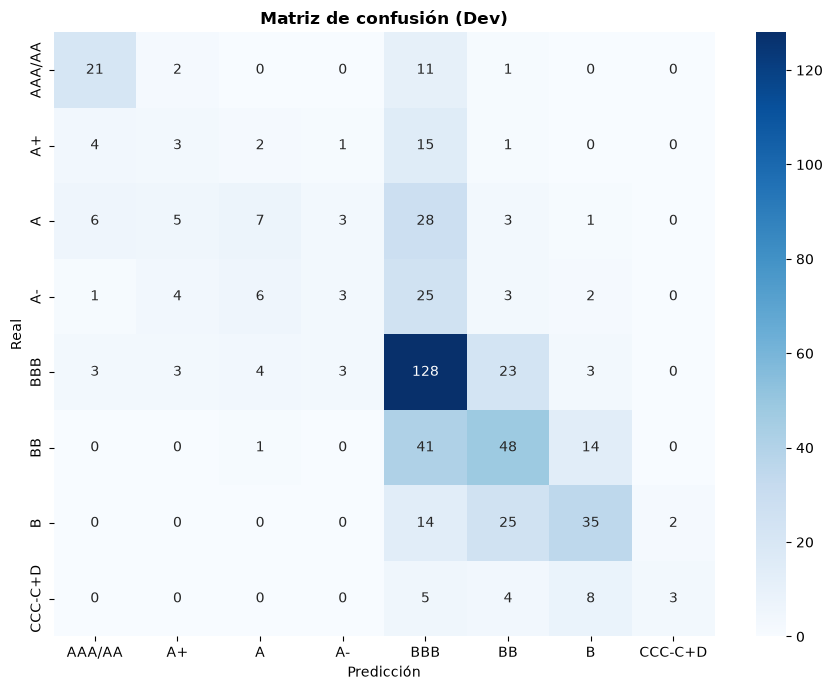

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_pred = np.argmax(model.predict(X_dev_proc, verbose=0), axis=1)
y_true = y_dev.to_numpy()

print(classification_report(y_true, y_pred, labels=X_ORDER, target_names=X_LABELS, zero_division=0))
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0):.4f}")
print(f"Exactitud ±1 clase (adyacente): {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f}%")

cm = confusion_matrix(y_true, y_pred, labels=X_ORDER)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (Dev)", fontweight='bold')
plt.tight_layout()
plt.show()

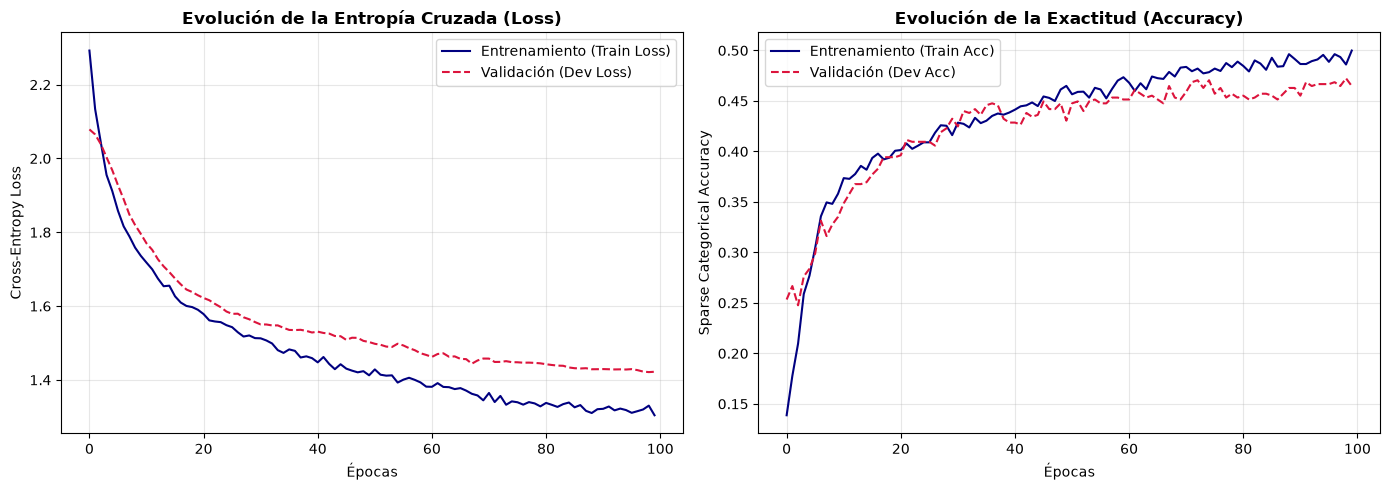

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafico de la Pérdida (Cross-Entropy)
ax1.plot(history.history['loss'], label='Entrenamiento (Train Loss)', color='navy')
ax1.plot(history.history['val_loss'], label='Validación (Dev Loss)', color='crimson', linestyle='--')
ax1.set_title("Evolución de la Entropía Cruzada (Loss)", fontweight='bold')
ax1.set_xlabel("Épocas")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico de la Exactitud (Accuracy)
ax2.plot(history.history['sparse_categorical_accuracy'], label='Entrenamiento (Train Acc)', color='navy')
ax2.plot(history.history['val_sparse_categorical_accuracy'], label='Validación (Dev Acc)', color='crimson', linestyle='--')
ax2.set_title("Evolución de la Exactitud (Accuracy)", fontweight='bold')
ax2.set_xlabel("Épocas")
ax2.set_ylabel("Sparse Categorical Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Comparación de optimizadores manualmente

,optimizador,CE_dev,Acc_dev,F1_macro,epocas
1,Momentum,1.5348,0.4381,0.3119,50
3,Adam,1.5411,0.4248,0.3101,50
2,RMSprop,1.5991,0.4095,0.2774,50
0,SGD,1.6794,0.3676,0.1963,50


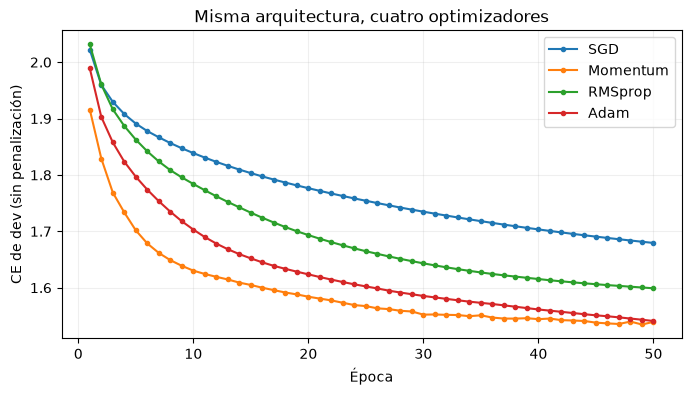

In [22]:
experimentos_opt = [
    ('SGD',      {'optimizador': 'sgd',      'learning_rate': 0.05}),
    ('Momentum', {'optimizador': 'momentum', 'learning_rate': 0.05, 'momentum': 0.9}),
    ('RMSprop',  {'optimizador': 'rmsprop',  'learning_rate': 0.001}),
    ('Adam',     {'optimizador': 'adam',     'learning_rate': 0.002}),
]

resultados_opt = []
historias_opt = {}

for nombre, params in experimentos_opt:
    modelo, hist = entrenar({'capas': (32,), **params}, epocas=50, paciencia=8)

    resultados_opt.append({
        'optimizador': nombre,
        **evaluar_dev(modelo),
        'epocas': len(hist.history['loss'])
    })
    historias_opt[nombre] = hist.history['val_ce']

display(pd.DataFrame(resultados_opt).sort_values('CE_dev'))

plt.figure(figsize=(8, 4))
for nombre, serie in historias_opt.items():
    plt.plot(range(1, len(serie) + 1), serie, marker='.', label=nombre)
plt.xlabel('Época')
plt.ylabel('CE de dev (sin penalización)')
plt.title('Misma arquitectura, cuatro optimizadores')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Regularización y batch normalization

,tecnica,CE_train,CE_dev,Acc_dev,F1_macro,brecha,epocas
4,BatchNorm,1.2475,1.4978,0.4400,0.3378,0.2503,50
0,Sin regularización,1.2941,1.4995,0.4724,0.3550,0.2054,50
2,L2,1.2993,1.5030,0.4686,0.3489,0.2037,50
1,L1,1.2953,1.5035,0.4705,0.3538,0.2082,50
3,Dropout 0.25,1.4813,1.5693,0.4343,0.2762,0.0880,50


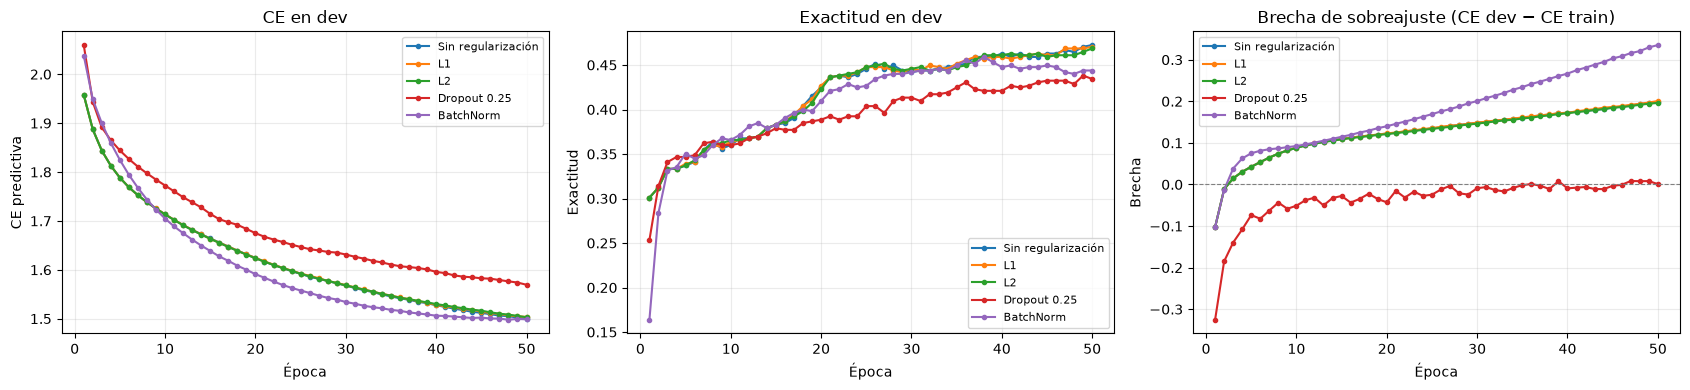

In [23]:
experimentos_reg = [
    ('Sin regularización', {}),
    ('L1',           {'l1': 1e-5}),
    ('L2',           {'l2': 1e-4}),
    ('Dropout 0.25', {'dropout': 0.25}),
    ('BatchNorm',    {'batchnorm': True}),
]

resultados_reg = []
historias_reg = {}

for nombre, cambio in experimentos_reg:
    modelo, hist = entrenar({'capas': (64, 32), **cambio}, epocas=50, paciencia=8)

    # CE en train, medida sin dropout y sin penalización (comparable con dev)
    logits_tr = modelo.predict(X_train_proc, verbose=0)
    ce_train = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(y_train, logits_tr).numpy()

    met = evaluar_dev(modelo)
    resultados_reg.append({
        'tecnica': nombre,
        'CE_train': round(float(ce_train), 4),
        **met,
        'brecha': round(met['CE_dev'] - float(ce_train), 4),   # dev - train
        'epocas': len(hist.history['loss'])
    })
    historias_reg[nombre] = hist.history

display(pd.DataFrame(resultados_reg).sort_values('CE_dev'))

# --- Gráficas: CE dev, exactitud dev y brecha (val_ce - ce) ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

for nombre, h in historias_reg.items():
    ep = range(1, len(h['val_ce']) + 1)
    ax[0].plot(ep, h['val_ce'], marker='.', label=nombre)
    ax[1].plot(ep, h['val_acc'], marker='.', label=nombre)
    brecha = np.array(h['val_ce']) - np.array(h['ce'])
    ax[2].plot(ep, brecha, marker='.', label=nombre)

ax[0].set(title='CE en dev', xlabel='Época', ylabel='CE predictiva')
ax[1].set(title='Exactitud en dev', xlabel='Época', ylabel='Exactitud')
ax[2].set(title='Brecha de sobreajuste (CE dev − CE train)', xlabel='Época', ylabel='Brecha')
ax[2].axhline(0, color='gray', lw=0.8, ls='--')

for a in ax:
    a.legend(fontsize=8)
    a.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Búsqueda aleatoria de hiperparámetros

Ensayo 1: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (32,), 'activacion': 'relu', 'optimizador': 'sgd', 'learning_rate': 0.03042, 'batchnorm': True}
Ensayo 2: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (16,), 'activacion': 'relu', 'optimizador': 'sgd', 'learning_rate': 0.01517, 'batchnorm': True}
Ensayo 3: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (16, 32), 'activacion': 'elu', 'optimizador': 'momentum', 'learning_rate': 0.01025, 'batchnorm': False}
Ensayo 4: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (16, 32), 'activacion': 'elu', 'optimizador': 'adam', 'learning_rate': 0.00151, 'batchnorm': False}
Ensayo 5: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (64, 16, 16), 'activacion': 'tanh', 'optimizador': 'rmsprop', 'learning_rate': 0.0002, 'batchnorm': True}
Ensayo 6: {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (16, 128, 16), 'activacion': 'tanh', 'optimizador': 'rmsprop', 'learning_rate': 0.00161, 'batchnorm': True}
Ensayo 7: {'dropout': 0.0, 'l1': 0.0, 'l2'

,ensayo,capas,activacion,optimizador,lr,batchnorm,CE_dev,Acc_dev,F1_macro,epocas
0,20,"(32, 64)",elu,adam,0.00783,False,1.4625,0.4857,0.3950,49
1,14,"(128, 16)",tanh,momentum,0.03838,False,1.4047,0.4933,0.3882,123
2,7,"(16, 16, 32)",tanh,rmsprop,0.00143,True,1.4884,0.4800,0.3633,77
3,6,"(16, 128, 16)",tanh,rmsprop,0.00161,True,1.4999,0.4438,0.3558,59
4,17,"(16, 64)",tanh,rmsprop,0.00335,True,1.4490,0.4419,0.3552,74
5,9,"(16, 32, 32)",relu,momentum,0.02190,False,1.5168,0.4667,0.3403,63
6,15,"(16, 16, 64, 64)",relu,rmsprop,0.00875,False,1.5880,0.4476,0.3347,31
7,4,"(16, 32)",elu,adam,0.00151,False,1.4860,0.4648,0.3344,150
8,11,"(64, 32, 128, 128)",elu,rmsprop,0.00014,False,1.5027,0.4533,0.3176,150
9,18,"(64,)",relu,rmsprop,0.00572,True,1.5319,0.4229,0.3106,42



Mejor configuración (ensayo 20, por F1_macro en dev):
{'dropout': 0.0, 'l1': 0.0, 'l2': 0.0, 'capas': (32, 64), 'activacion': 'elu', 'optimizador': 'adam', 'learning_rate': 0.00783, 'batchnorm': False}


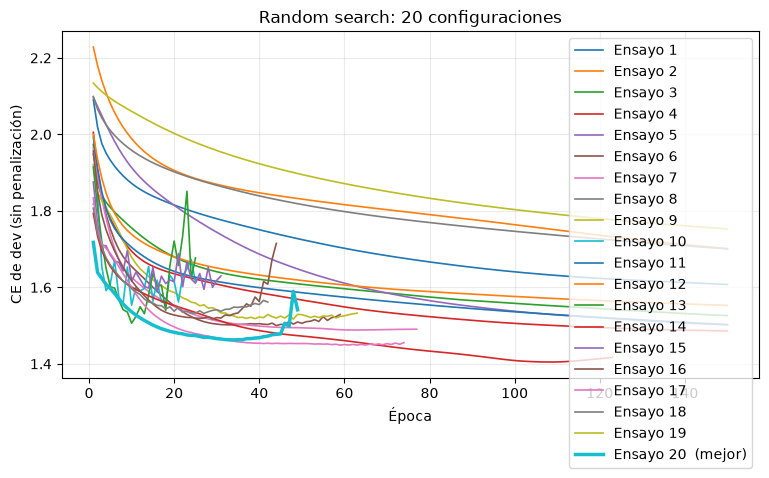

In [24]:
import random
 
CRITERIO  = 'F1_macro'   # mayor es mejor
DESEMPATE = 'CE_dev'     # menor es mejor
FIJOS     = {'dropout': 0.0, 'l1': 0.0, 'l2': 0.0}
 
N_ENSAYOS = 20
EPOCAS    = 150          # los modelos de la sección 6 no habían convergido a 50
PACIENCIA = 15
 
ESPACIO = {
    'n_capas':     [1, 2, 3, 4],
    'neuronas':    [16, 32, 64, 128],              # se sortea por capa
    'activacion':  ['relu', 'tanh', 'elu'],
    'optimizador': ['sgd', 'momentum', 'rmsprop', 'adam'],
    'batchnorm':   [True, False],
}
# SGD/Momentum necesitan lr más grande que RMSprop/Adam, por eso rangos distintos (log-uniforme)
RANGO_LR = {
    'sgd':      (1e-3, 1e-1),
    'momentum': (1e-3, 1e-1),
    'rmsprop':  (1e-4, 1e-2),
    'adam':     (1e-4, 1e-2),
}
 
def sortear_cfg(rng):
    n_capas = rng.choice(ESPACIO['n_capas'])
    opt = rng.choice(ESPACIO['optimizador'])
    lo, hi = RANGO_LR[opt]
    lr = float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
    return {
        **FIJOS,
        'capas':         tuple(rng.choice(ESPACIO['neuronas']) for _ in range(n_capas)),
        'activacion':    rng.choice(ESPACIO['activacion']),
        'optimizador':   opt,
        'learning_rate': round(lr, 5),
        'batchnorm':     rng.choice(ESPACIO['batchnorm']),
    }
 
# %% Ejecución de los 5 ensayos (solo train y dev)
rng = random.Random(42)   # misma semilla -> mismos 5 sorteos
resultados_rs, historias_rs, configs_rs = [], {}, {}
 
for i in range(1, N_ENSAYOS + 1):
    cfg = sortear_cfg(rng)
    print(f"Ensayo {i}: {cfg}")
    modelo, hist = entrenar(cfg, epocas=EPOCAS, paciencia=PACIENCIA)
 
    resultados_rs.append({
        'ensayo':      i,
        'capas':       cfg['capas'],
        'activacion':  cfg['activacion'],
        'optimizador': cfg['optimizador'],
        'lr':          cfg['learning_rate'],
        'batchnorm':   cfg['batchnorm'],
        **evaluar_dev(modelo),
        'epocas':      len(hist.history['loss']),
    })
    historias_rs[i] = hist.history['val_ce']
    configs_rs[i] = cfg
 
tabla_rs = (pd.DataFrame(resultados_rs)
              .sort_values([CRITERIO, DESEMPATE], ascending=[False, True])
              .reset_index(drop=True))
display(tabla_rs)
 
mejor_ensayo = int(tabla_rs.loc[0, 'ensayo'])
mejor_cfg = configs_rs[mejor_ensayo]
print(f"\nMejor configuración (ensayo {mejor_ensayo}, por {CRITERIO} en dev):\n{mejor_cfg}")
 
# %% Curvas de CE en dev por ensayo
plt.figure(figsize=(9, 4.5))
for i, serie in historias_rs.items():
    etiqueta = f"Ensayo {i}" + ("  (mejor)" if i == mejor_ensayo else "")
    plt.plot(range(1, len(serie) + 1), serie,
             lw=2.5 if i == mejor_ensayo else 1.2, label=etiqueta)
plt.xlabel('Época')
plt.ylabel('CE de dev (sin penalización)')
plt.title('Random search: 20 configuraciones')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Evaluación final en Test y conclusiones

Epoch 1/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - acc: 0.3283 - ce: 1.8161 - loss: 1.8161 - val_acc: 0.3771 - val_ce: 1.7177 - val_loss: 1.7177
Epoch 2/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.3812 - ce: 1.6433 - loss: 1.6433 - val_acc: 0.3848 - val_ce: 1.6388 - val_loss: 1.6388
Epoch 3/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.3945 - ce: 1.5969 - loss: 1.5969 - val_acc: 0.4038 - val_ce: 1.6234 - val_loss: 1.6234
Epoch 4/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.4011 - ce: 1.5636 - loss: 1.5636 - val_acc: 0.4038 - val_ce: 1.6076 - val_loss: 1.6076
Epoch 5/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.4111 - ce: 1.5361 - loss: 1.5361 - val_acc: 0.4171 - val_ce: 1.5971 - val_loss: 1.5971
Epoch 6/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.4209 - ce: 1.5115 - loss: 1.5115 - val_acc: 0.4267 - val_ce: 1.5840 - val_loss: 1.5840
Epoch 7/150
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - acc: 0.4240 - ce: 1.4899 - loss: 1.4899 - val_acc: 0.4324 - val_

Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_98 (Dense)                │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_68 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_69 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,162 (43.61 KB)

 Trainable params: 3,720 (14.53 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,442 (29.07 KB)

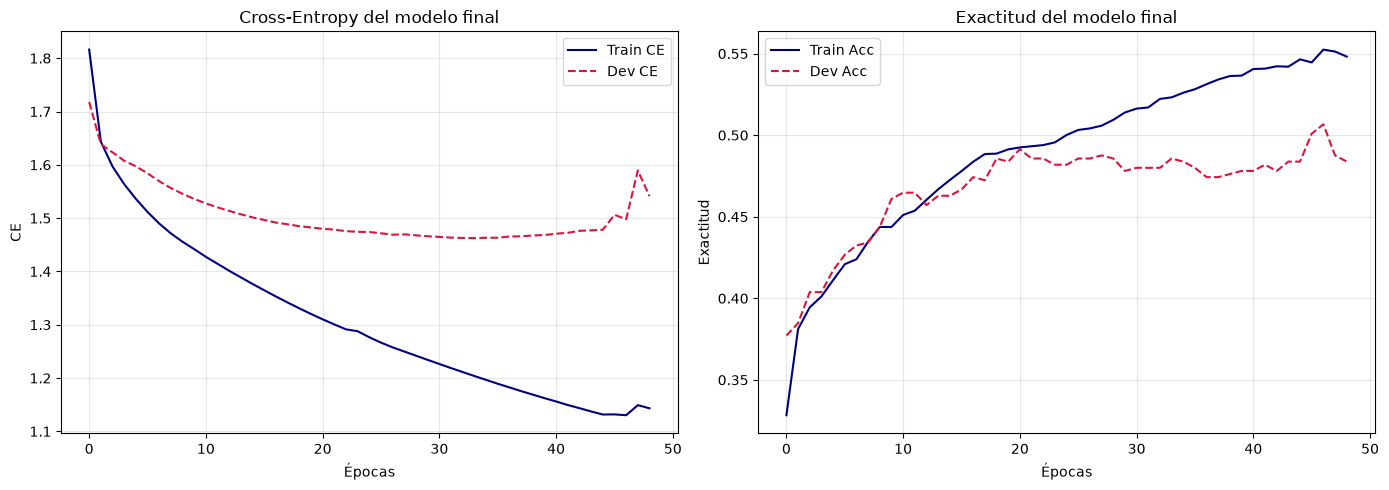

CE en test:        1.5173
Exactitud en test: 43.73%
Macro-F1 en test:  0.3518
Exactitud ±1 clase (adyacente): 74.14%

              precision    recall  f1-score   support

      AAA/AA       0.57      0.34      0.43        35
          A+       0.26      0.20      0.23        25
           A       0.24      0.17      0.20        54
          A-       0.00      0.00      0.00        43
         BBB       0.45      0.68      0.54       168
          BB       0.46      0.41      0.43       104
           B       0.51      0.49      0.50        77
     CCC-C+D       0.53      0.45      0.49        20

    accuracy                           0.44       526
   macro avg       0.38      0.34      0.35       526
weighted avg       0.40      0.44      0.41       526



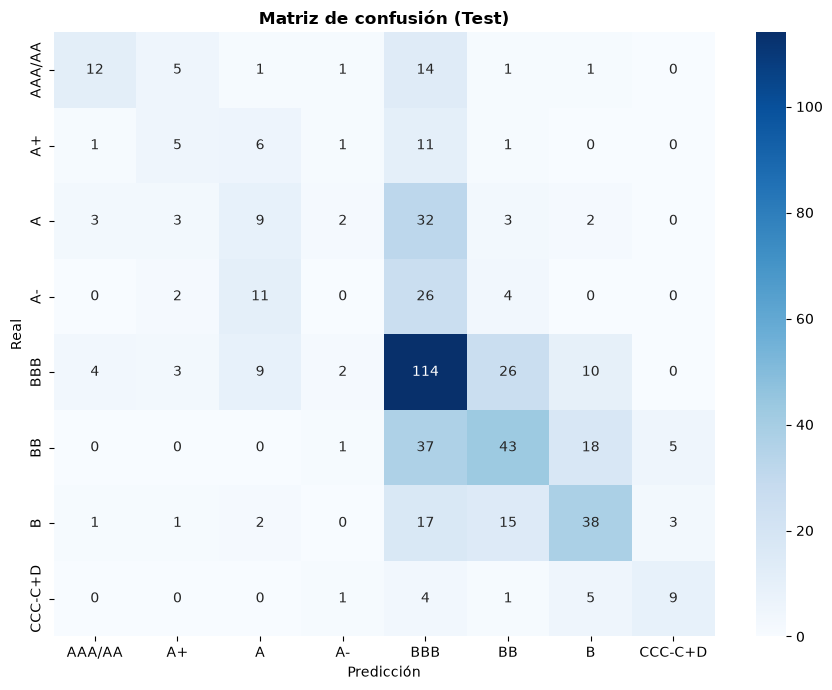

In [25]:
modelo_final, hist_final = entrenar(mejor_cfg, epocas=EPOCAS, paciencia=PACIENCIA, verbose=1)
modelo_final.summary()
 
# %% Curvas del modelo final
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(hist_final.history['ce'], label='Train CE', color='navy')
ax1.plot(hist_final.history['val_ce'], label='Dev CE', color='crimson', linestyle='--')
ax1.set(title='Cross-Entropy del modelo final', xlabel='Épocas', ylabel='CE')
ax2.plot(hist_final.history['acc'], label='Train Acc', color='navy')
ax2.plot(hist_final.history['val_acc'], label='Dev Acc', color='crimson', linestyle='--')
ax2.set(title='Exactitud del modelo final', xlabel='Épocas', ylabel='Exactitud')
for a in (ax1, ax2):
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()
 
# %% Evaluación ÚNICA en test
from sklearn.metrics import classification_report, confusion_matrix, f1_score
 
logits_test = modelo_final.predict(X_test_proc, verbose=0)
y_pred = logits_test.argmax(axis=1)
y_true = y_test.to_numpy()
 
ce_test = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)(y_true, logits_test).numpy()
print(f"CE en test:        {ce_test:.4f}")
print(f"Exactitud en test: {(y_pred == y_true).mean() * 100:.2f}%")
print(f"Macro-F1 en test:  {f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0):.4f}")
print(f"Exactitud ±1 clase (adyacente): {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f}%\n")
 
print(classification_report(y_true, y_pred, labels=X_ORDER,
                            target_names=X_LABELS, zero_division=0))
 
cm = confusion_matrix(y_true, y_pred, labels=X_ORDER)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión (Test)", fontweight='bold')
plt.tight_layout()
plt.show()